# Part 1: FDIC Data Acquisition, Verification & Lakehouse Storage Architecture
This notebook verifies the reproducible acquisition of 170 quarters (1984Q1–2026Q2) of FDIC Call Report data, audits manifest completeness against API totals, and benchmarks our Hive-partitioned Zstandard Parquet Bronze layer against raw CSV and unpartitioned layouts.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import polars as pl
from src.bfews.quality import audit_manifest

manifest_check = audit_manifest()
print('Manifest Audit Summary:', manifest_check)

Manifest Audit Summary: {'quarters_downloaded': 170, 'total_manifest_rows': 1682616, 'incomplete_quarters': [], 'api_mismatch_quarters': []}


In [2]:
bench_df = pl.read_csv('../outputs/tables/part1_storage_benchmark.csv')
print(bench_df)
f32_df = pl.read_csv('../outputs/tables/part1_float32_check.csv')
print('\n=== Float32 Precision Loss Check (Justifies Float64) ===')
print(f32_df)
bronze_files = list(Path('../data/bronze/financials').rglob('*.parquet'))
print(f'Bronze partition count: {len(bronze_files)} files across {len({p.parent for p in bronze_files})} year folders')

shape: (6, 7)
┌────────────────┬─────────┬─────────┬─────────────┬───────────────┬───────────────┬───────────────┐
│ format         ┆ size_mb ┆ write_s ┆ full_read_s ┆ read_3_cols_s ┆ filter_2023_s ┆ compression_v │
│ ---            ┆ ---     ┆ ---     ┆ ---         ┆ ---           ┆ ---           ┆ s_csv         │
│ str            ┆ f64     ┆ f64     ┆ f64         ┆ f64           ┆ f64           ┆ ---           │
│                ┆         ┆         ┆             ┆               ┆               ┆ f64           │
╞════════════════╪═════════╪═════════╪═════════════╪═══════════════╪═══════════════╪═══════════════╡
│ CSV            ┆ 425.7   ┆ 0.77    ┆ 0.683       ┆ 0.22          ┆ 0.988         ┆ 1.0           │
│ (uncompressed) ┆         ┆         ┆             ┆               ┆               ┆               │
│ Parquet single ┆ 210.8   ┆ 0.296   ┆ 0.229       ┆ 0.033         ┆ 0.031         ┆ 2.02          │
│ file, Snappy   ┆         ┆         ┆             ┆               ┆         

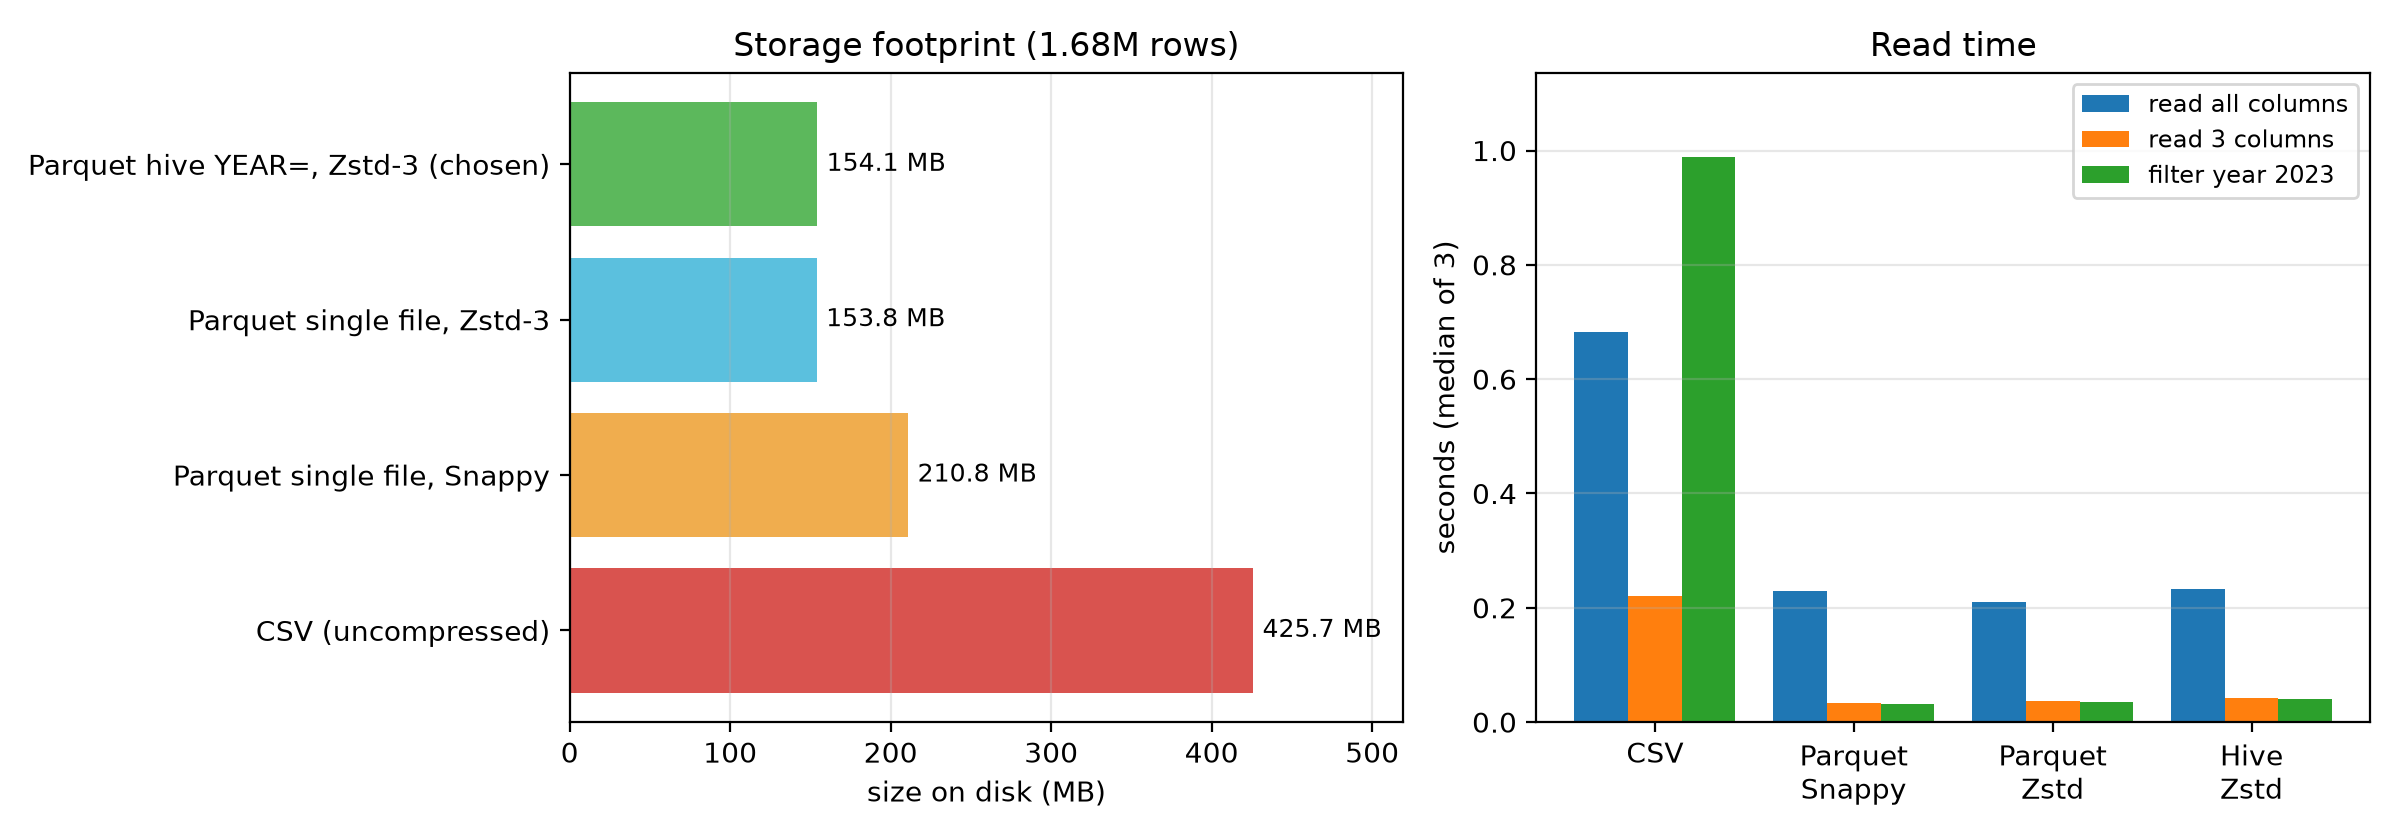

In [3]:
from IPython.display import Image, display
display(Image(filename='../outputs/figures/part1_storage_comparison.png'))